# 02 — Coupled Multi-Head DNN with SHAP Feature Analysis
**Thesis pipeline, part 2 of 3.** Adapts Yang et al., *IEEE Photonics J.* 18(1) 2026
to categorical inverse design.

Contents: shared-trunk multi-head DNN under **leave-structure-out** GroupKFold CV
with noise augmentation; SHAP attribution (per response / per wavelength);
global wavelength selection (top third); reduced model.
**Produces Figures 1-4** (`fig1`-`fig4` + `fig3b`) and `results_summary.json`.

> Runtime: ~10-15 min on CPU.

In [1]:
# ---- Shared configuration -------------------------------------------------
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
torch.manual_seed(42); np.random.seed(42)

DATA_PATH = "/kaggle/input/datasets/fahmidaalamtamim/dataset-recalculated/FINAL_PCF_DATASET_recalculated.xlsx"   # <-- adjust (e.g. /kaggle/input/.../FINAL_PCF_DATASET.xlsx)
# Save everything here
PROCESSED = "/kaggle/input/datasets/fahmidaalamtamim/output/processed_dataset (2).npz"
RESPONSES = ["real ewfd", "imag ewfd", "Aeff", "dispersion(y)",
             "non linearity(y)", "conf loss(y)"]
TARGETS = ["Ratio", "Shape", "No. of rings", "Anomaly position"]
OUT_DIR = Path("/kaggle/working/output_model_comparison")
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_AUG = 40; NOISE_FRAC = 0.02; N_FOLDS = 5
EPOCHS = 300; PATIENCE = 30; LR = 1e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


In [2]:
# ---- Load the processed dataset from Notebook 01 ---------------------------
z = np.load(PROCESSED, allow_pickle=True)
X = z["X"]; wavelengths = z["wavelengths"]; feat_names = list(z["feat_names"])
y = {t: z[f"y_{i}"] for i, t in enumerate(TARGETS)}
classes = {t: z[f"c_{i}"] for i, t in enumerate(TARGETS)}
n_classes = {t: len(classes[t]) for t in TARGETS}
n_wl = len(wavelengths)
print(f"{X.shape[0]} structures, {X.shape[1]} features ({len(RESPONSES)} responses x {n_wl} wavelengths)")
print("classes:", n_classes)

54 structures, 528 features (6 responses x 88 wavelengths)
classes: {'Ratio': 2, 'Shape': 3, 'No. of rings': 3, 'Anomaly position': 3}


## 2.1 Model and training utilities

In [3]:
class MultiHeadInverseNet(nn.Module):
    def __init__(self, in_dim, n_classes, hidden=(128, 64), p_drop=0.1):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(),
                       nn.Dropout(p_drop)]
            d = h
        self.trunk = nn.Sequential(*layers)
        self.heads = nn.ModuleDict(
            {t.replace(".", "_"): nn.Linear(d, k) for t, k in n_classes.items()})

    def forward(self, x):
        z = self.trunk(x)
        return {t: head(z) for t, head in self.heads.items()}


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def augment(X, ys, n_copies, noise_frac, rng):
    stds = X.std(axis=0, keepdims=True) + 1e-12
    Xa = [X]
    for _ in range(n_copies):
        Xa.append(X + rng.normal(0, noise_frac, X.shape) * stds)
    Xa = np.vstack(Xa)
    ya = {t: np.tile(v, n_copies + 1) for t, v in ys.items()}
    return Xa, ya


def train_one(model, Xtr, ytr, Xva, yva, epochs=EPOCHS, patience=PATIENCE):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    ce = nn.CrossEntropyLoss()
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32, device=DEVICE)
    Xva_t = torch.tensor(Xva, dtype=torch.float32, device=DEVICE)
    ytr_t = {t: torch.tensor(v, dtype=torch.long, device=DEVICE)
             for t, v in ytr.items()}
    yva_t = {t: torch.tensor(v, dtype=torch.long, device=DEVICE)
             for t, v in yva.items()}

    best, best_state, wait = np.inf, None, 0
    n = len(Xtr_t)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, 256):
            idx = perm[i:i + 256]
            if len(idx) < 2:          # BatchNorm needs >1 sample
                continue
            opt.zero_grad()
            out = model(Xtr_t[idx])
            loss = sum(ce(out[t.replace(".", "_")], ytr_t[t][idx])
                       for t in ytr)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            out = model(Xva_t)
            vloss = sum(ce(out[t.replace(".", "_")], yva_t[t]).item()
                        for t in yva)
        if vloss < best - 1e-5:
            best, wait = vloss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model


## 2.2 Leave-structure-out cross-validation
Each structure is its own group: no augmented copy of a held-out structure ever
appears in training. This is the protocol that makes results defensible at n=53.

In [4]:
def run_cv(X, y, n_classes, feat_idx=None, tag="full"):
    """Leave-structure-out GroupKFold CV. Returns per-head accuracy and a
    model trained on all data (for SHAP)."""
    if feat_idx is None:
        feat_idx = np.arange(X.shape[1])
    Xs = X[:, feat_idx]
    groups = np.arange(len(Xs))          # each structure is its own group
    gkf = GroupKFold(n_splits=N_FOLDS)
    rng = np.random.default_rng(0)
    accs = {t: [] for t in TARGETS}
    t0 = time.time()
    infer_times = []

    for tr, va in gkf.split(Xs, groups=groups):
        scaler = StandardScaler().fit(Xs[tr])
        Xtr = scaler.transform(Xs[tr])
        Xva = scaler.transform(Xs[va])
        ytr = {t: v[tr] for t, v in y.items()}
        yva = {t: v[va] for t, v in y.items()}
        Xtr_a, ytr_a = augment(Xtr, ytr, N_AUG, NOISE_FRAC, rng)

        model = MultiHeadInverseNet(len(feat_idx), n_classes)
        model = train_one(model, Xtr_a, ytr_a, Xva, yva)

        model.eval()
        with torch.no_grad():
            tic = time.time()
            out = model(torch.tensor(Xva, dtype=torch.float32, device=DEVICE))
            infer_times.append((time.time() - tic) / len(va))
        for t in TARGETS:
            pred = out[t.replace(".", "_")].argmax(1).cpu().numpy()
            accs[t].append((pred == yva[t]).mean())

    cv_time = time.time() - t0
    acc_mean = {t: float(np.mean(v)) for t, v in accs.items()}
    acc_std = {t: float(np.std(v)) for t, v in accs.items()}

    # final model on ALL structures (for SHAP / deployment)
    scaler = StandardScaler().fit(Xs)
    Xall = scaler.transform(Xs)
    Xall_a, yall_a = augment(Xall, y, N_AUG, NOISE_FRAC, rng)
    final = MultiHeadInverseNet(len(feat_idx), n_classes)
    final = train_one(final, Xall_a, yall_a, Xall, y)
    final.eval()

    print(f"[{tag}] CV acc: " +
          ", ".join(f"{t}={acc_mean[t]:.3f}±{acc_std[t]:.3f}" for t in TARGETS))
    return {"acc_mean": acc_mean, "acc_std": acc_std,
            "cv_time_s": cv_time,
            "infer_ms_per_design": float(np.mean(infer_times) * 1e3),
            "n_params": count_params(final)}, final, scaler, Xall


In [5]:
res_full, model_full, scaler_full, Xall = run_cv(X, y, n_classes, tag="full")

[full] CV acc: Ratio=0.964±0.045, Shape=0.927±0.106, No. of rings=0.296±0.156, Anomaly position=0.333±0.090


## 2.3 SHAP attribution (GradientExplainer, per head)

In [6]:
def shap_attribution(model, Xall, n_classes):
    import shap

    class HeadWrapper(nn.Module):
        def __init__(self, m, head):
            super().__init__()
            self.m, self.head = m, head

        def forward(self, x):
            return self.m(x)[self.head]

    Xt = torch.tensor(Xall, dtype=torch.float32, device=DEVICE)
    per_head = {}
    for t in TARGETS:
        wrapper = HeadWrapper(model, t.replace(".", "_")).to(DEVICE).eval()
        expl = shap.GradientExplainer(wrapper, Xt)
        sv = expl.shap_values(Xt)                    # list per class or array
        if isinstance(sv, list):
            mag = np.mean([np.abs(s) for s in sv], axis=0)
        else:                                        # (n, feat, class)
            mag = np.abs(sv).mean(axis=-1)
        per_head[t] = mag.mean(axis=0)               # (n_features,)
    global_imp = np.mean([per_head[t] for t in TARGETS], axis=0)
    return per_head, global_imp


def aggregate(imp, n_resp, n_wl):
    """(528,) -> per-response totals and per-wavelength totals."""
    M = imp.reshape(n_resp, n_wl)
    return M.sum(axis=1), M.sum(axis=0), M


In [7]:
shap_per_head, global_imp = shap_attribution(model_full, Xall, n_classes)
resp_imp, wl_imp, M = aggregate(global_imp, len(RESPONSES), n_wl)

## 2.4 Global wavelength selection (top third) and reduced model
Mirrors the source paper's removal of the bottom two-thirds of features.

In [8]:
SHAP_KEEP_FRAC = 1/3
k = max(3, int(round(n_wl * SHAP_KEEP_FRAC)))
selected_wl_idx = np.sort(np.argsort(wl_imp)[::-1][:k])
sel_wl = wavelengths[selected_wl_idx]
print(f"Selected {k}/{n_wl} wavelengths:", np.round(sel_wl, 2).tolist())
feat_idx = np.concatenate([r * n_wl + selected_wl_idx for r in range(len(RESPONSES))])
res_red, model_red, _, _ = run_cv(X, y, n_classes, feat_idx=feat_idx, tag="reduced")
param_drop = 1 - res_red["n_params"] / res_full["n_params"]
print(f"Parameter reduction: {param_drop:.1%} ({res_full['n_params']:,} -> {res_red['n_params']:,})")

Selected 29/88 wavelengths: [0.66, 0.75, 0.77, 0.78, 0.79, 0.85, 0.86, 0.87, 0.89, 0.99, 1.02, 1.04, 1.06, 1.08, 1.1, 1.12, 1.13, 1.14, 1.19, 1.23, 1.33, 1.34, 1.39, 1.4, 1.42, 1.46, 1.47, 1.49, 1.51]
[reduced] CV acc: Ratio=1.000±0.000, Shape=0.964±0.045, No. of rings=0.371±0.163, Anomaly position=0.358±0.189
Parameter reduction: 58.8% (77,067 -> 31,755)


## 2.5 Figures 1-4
Fig 1 per-head accuracy (full vs reduced) · Fig 2 response importance ·
Fig 3 wavelength importance + selected bands · Fig 3b response x wavelength heatmap ·
Fig 4 top-15 features per head.

In [9]:
def make_plots(res_full, res_red, resp_imp, wl_imp, M, wavelengths,
               selected_wl_idx, shap_per_head, feat_names):
    # Fig 1: per-head accuracy full vs reduced
    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(TARGETS))
    w = 0.35
    ax.bar(x - w / 2, [res_full["acc_mean"][t] for t in TARGETS], w,
           yerr=[res_full["acc_std"][t] for t in TARGETS], capsize=3,
           label=f"Full (528 feat, {res_full['n_params']:,} params)")
    ax.bar(x + w / 2, [res_red["acc_mean"][t] for t in TARGETS], w,
           yerr=[res_red["acc_std"][t] for t in TARGETS], capsize=3,
           label=f"Reduced ({len(selected_wl_idx)*len(RESPONSES)} feat, "
                 f"{res_red['n_params']:,} params)")
    ax.axhline(1 / 3, ls="--", c="gray", lw=1, label="chance (3-class)")
    ax.axhline(1 / 2, ls=":", c="gray", lw=1, label="chance (Ratio)")
    ax.set_xticks(x, ["Ratio", "Shape", "Rings", "Anomaly"])
    ax.set_ylabel("Leave-structure-out CV accuracy")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig1_head_accuracy.png", dpi=200)

    # Fig 2: SHAP importance per optical response
    fig, ax = plt.subplots(figsize=(7, 4))
    order = np.argsort(resp_imp)[::-1]
    ax.barh([RESPONSES[i] for i in order][::-1], resp_imp[order][::-1],
            color="steelblue")
    ax.set_xlabel("Total mean |SHAP| (summed over wavelengths)")
    ax.set_title("Which optical responses drive the inverse design?")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig2_response_importance.png", dpi=200)

    # Fig 3: wavelength importance + selected bands
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(wavelengths, wl_imp, "-o", ms=3, color="steelblue",
            label="mean |SHAP| per wavelength")
    ax.scatter(wavelengths[selected_wl_idx], wl_imp[selected_wl_idx],
               color="crimson", zorder=5, s=25,
               label=f"selected {len(selected_wl_idx)} wavelengths")
    ax.set_xlabel("Wavelength (µm)")
    ax.set_ylabel("mean |SHAP|")
    ax.set_title("Minimum spectral characterization: decision-critical bands")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig3_wavelength_importance.png", dpi=200)

    # Fig 3b: response x wavelength heatmap
    fig, ax = plt.subplots(figsize=(9, 3.5))
    im = ax.imshow(M, aspect="auto", cmap="viridis",
                   extent=[wavelengths[0], wavelengths[-1], len(RESPONSES) - .5, -.5])
    ax.set_yticks(range(len(RESPONSES)), RESPONSES)
    ax.set_xlabel("Wavelength (µm)")
    fig.colorbar(im, label="mean |SHAP|")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig3b_shap_heatmap.png", dpi=200)

    # Fig 4: top-15 features per head
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, t in zip(axes.ravel(), TARGETS):
        imp = shap_per_head[t]
        top = np.argsort(imp)[::-1][:15]
        ax.barh([feat_names[i] for i in top][::-1], imp[top][::-1],
                color="mediumseagreen")
        ax.set_title(t, fontsize=10)
        ax.tick_params(labelsize=7)
    fig.suptitle("Top-15 SHAP features per design head")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig4_shap_top_features.png", dpi=200)

    


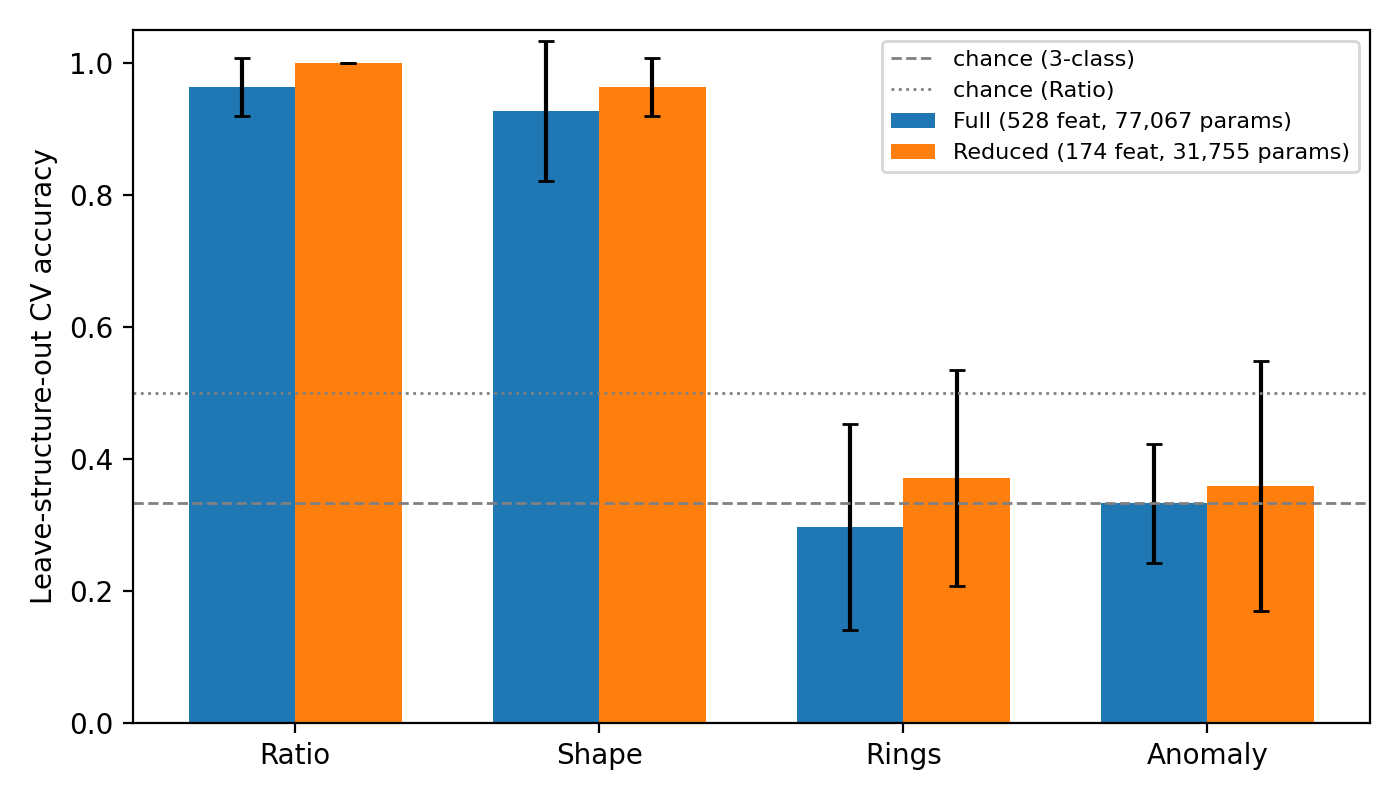

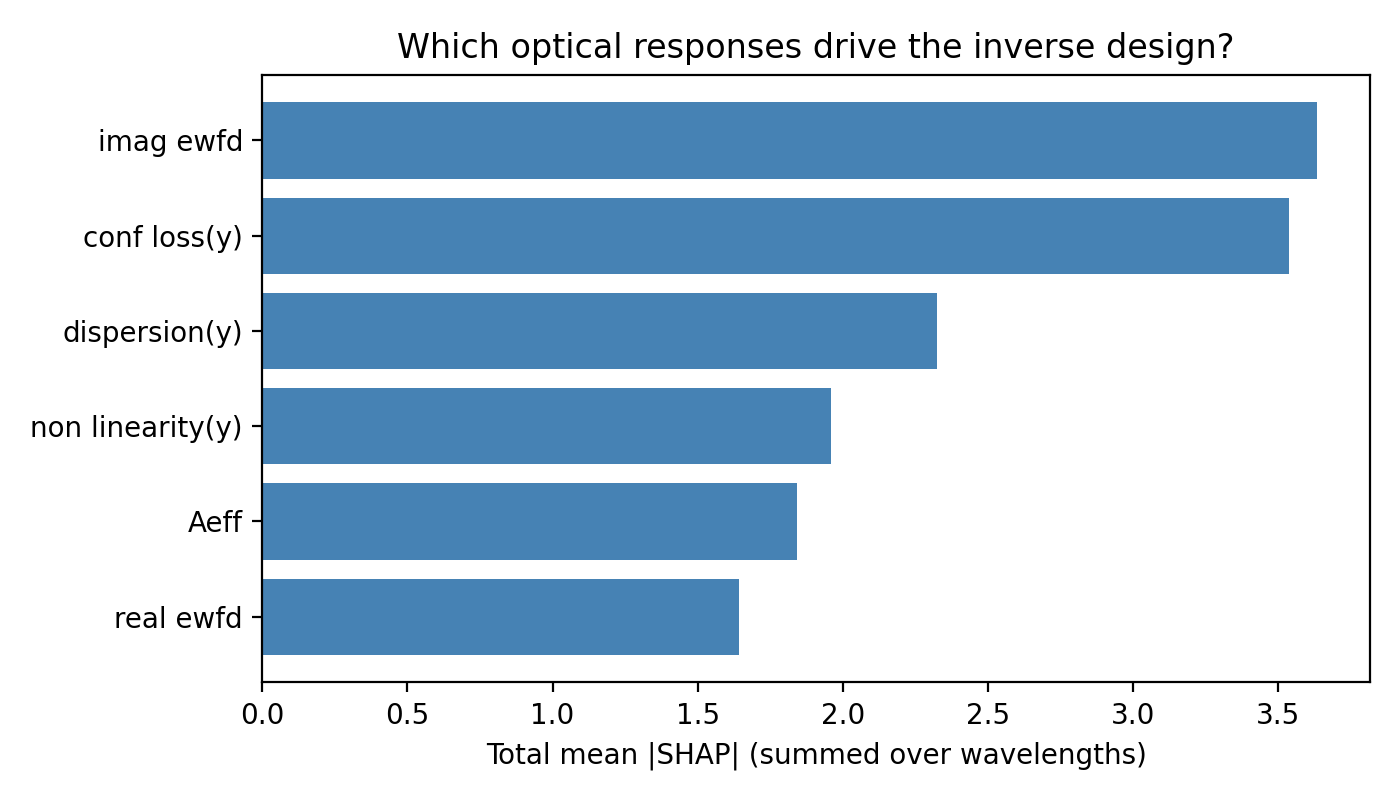

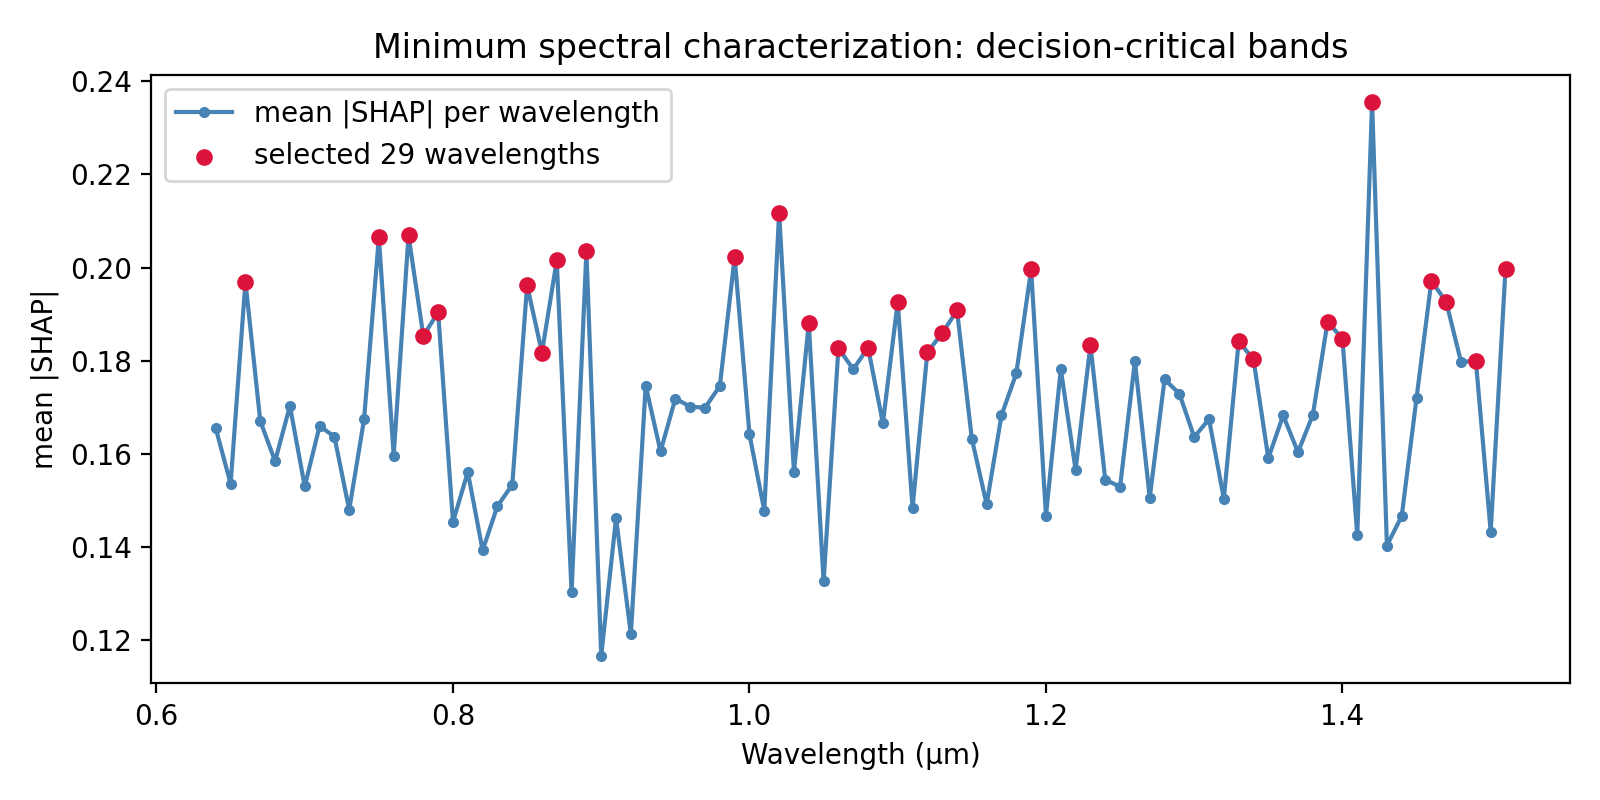

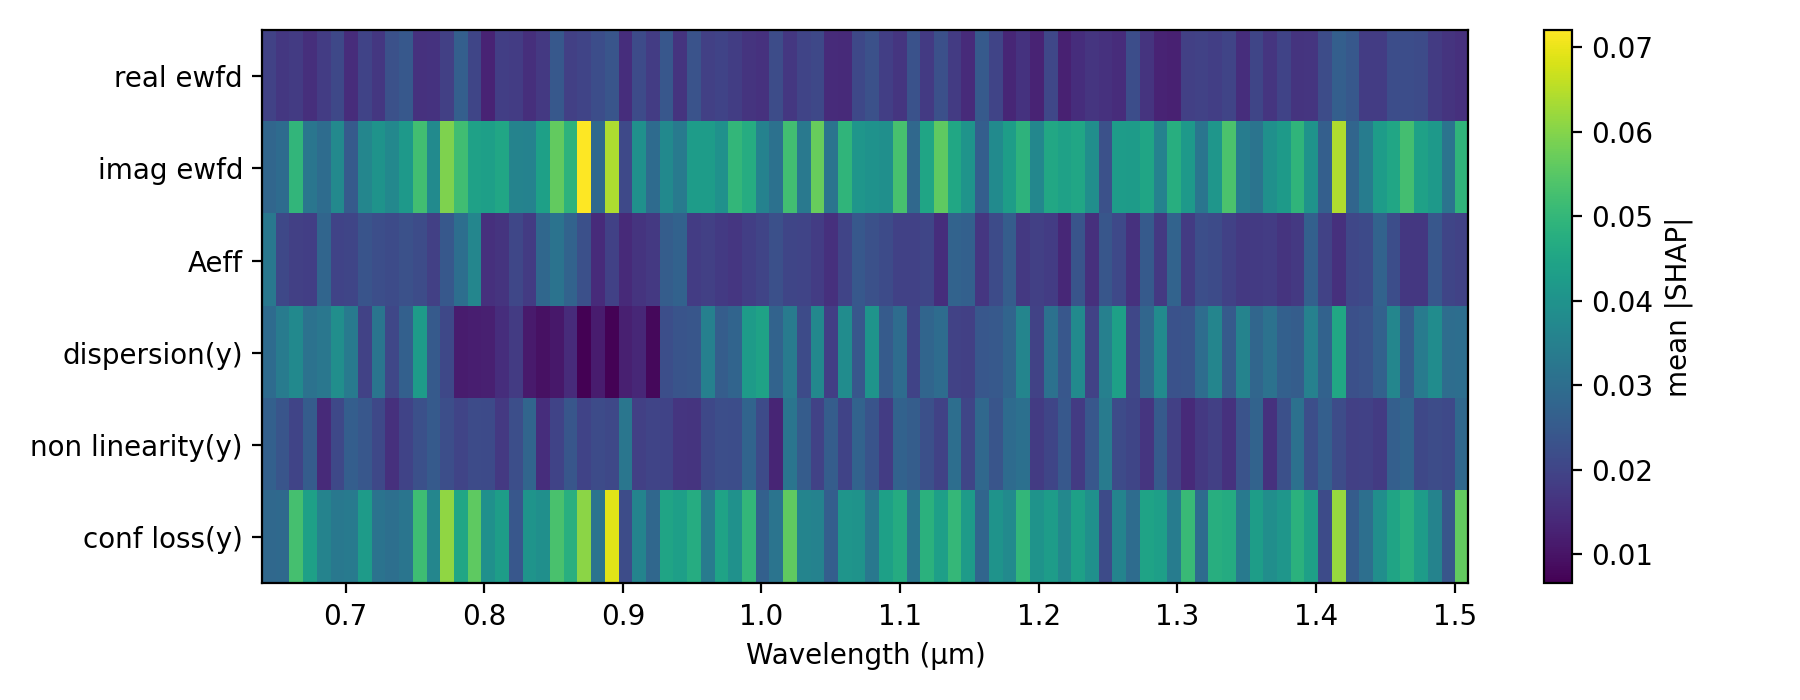

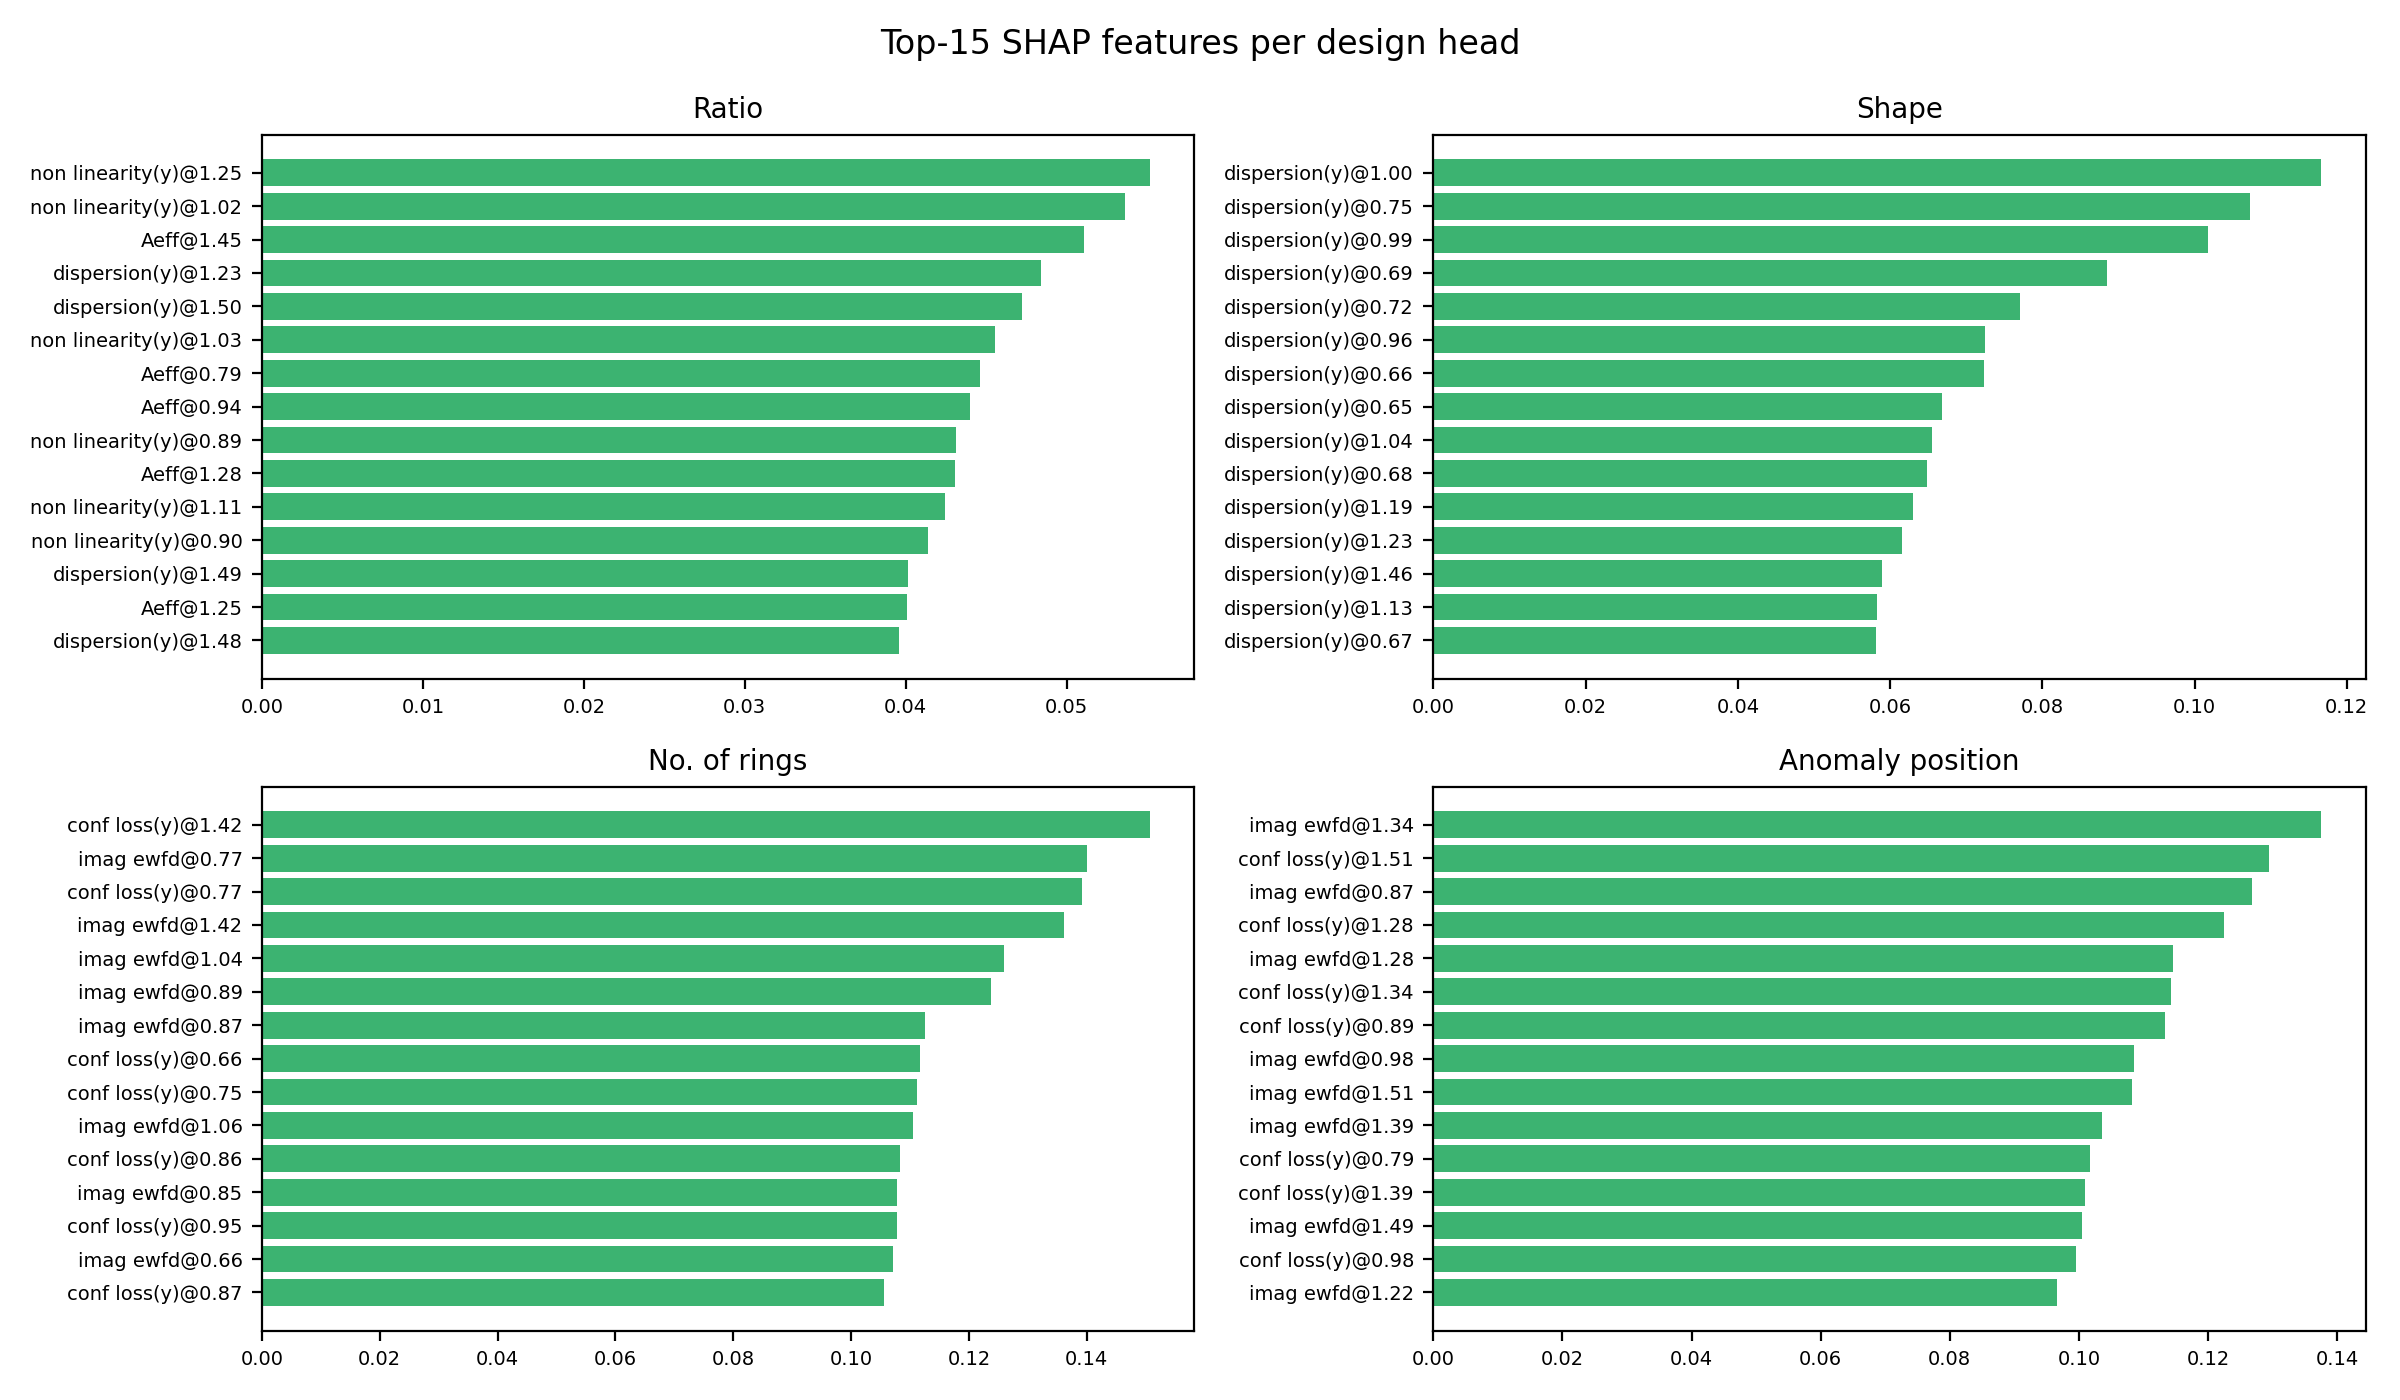

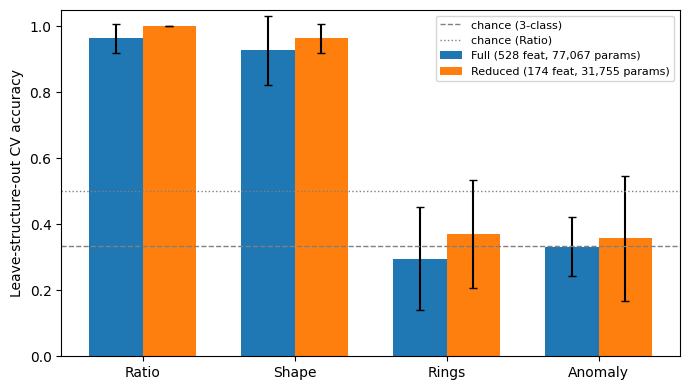

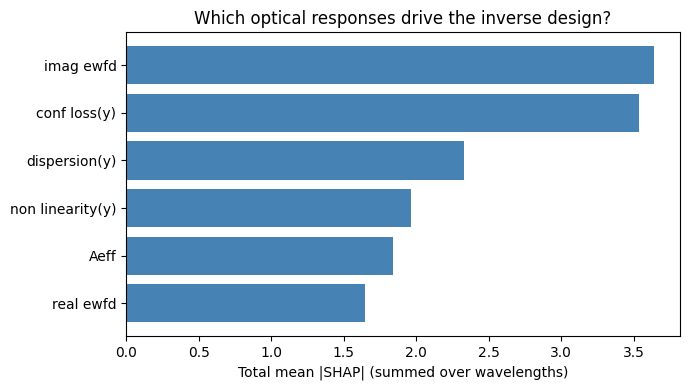

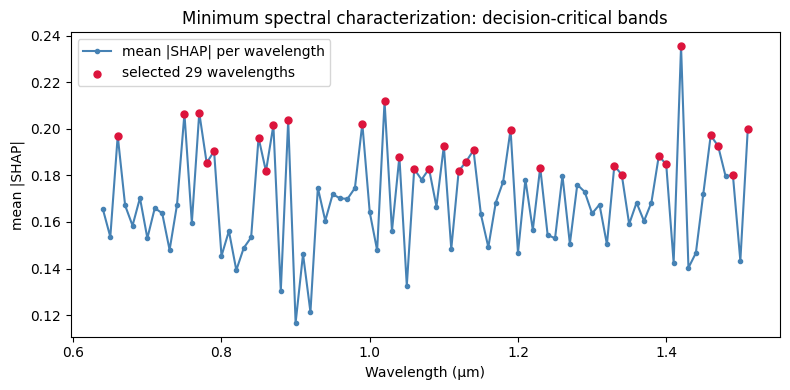

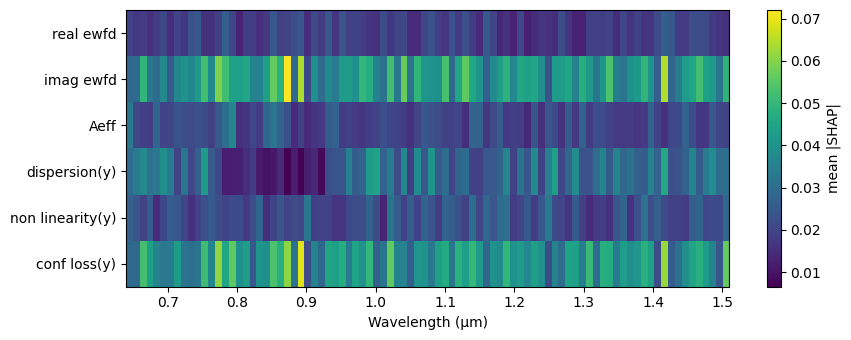

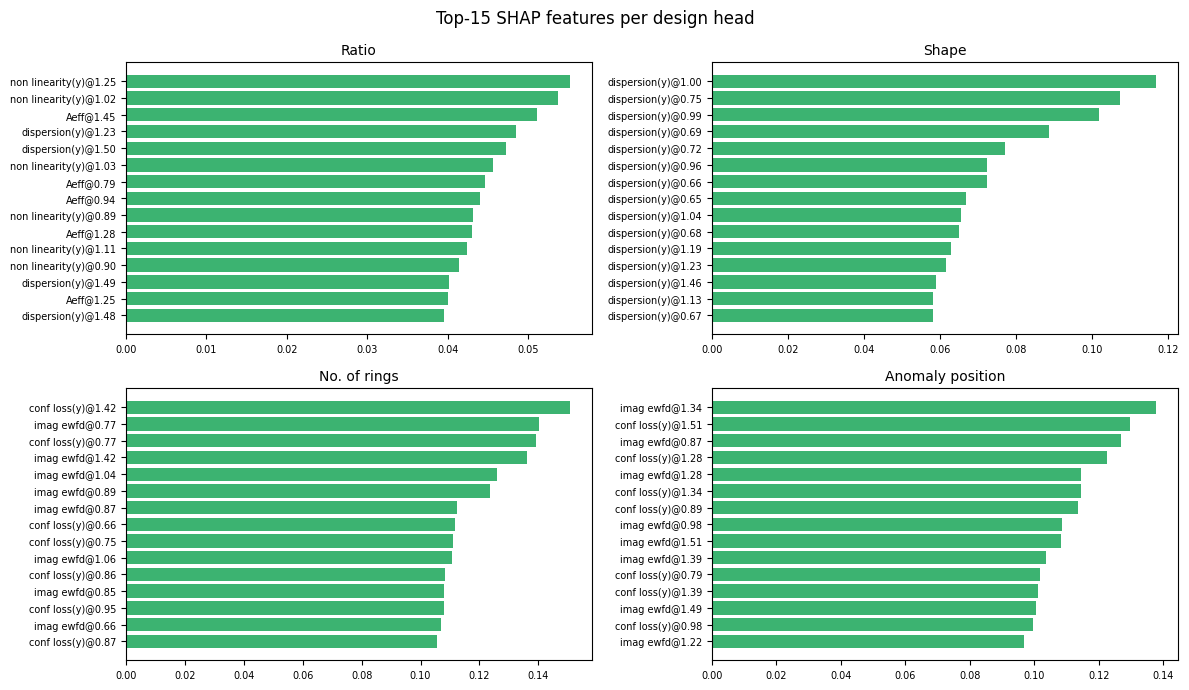

In [10]:
make_plots(res_full, res_red, resp_imp, wl_imp, M, wavelengths,
           selected_wl_idx, shap_per_head, feat_names)
from IPython.display import Image, display
for f in ["fig1_head_accuracy", "fig2_response_importance", "fig3_wavelength_importance",
          "fig3b_shap_heatmap", "fig4_shap_top_features"]:
    display(Image(str(OUT_DIR / f"{f}.png")))

## 2.6 Summary JSON

In [11]:
summary = {
    "n_structures": int(len(X)),
    "n_features_full": int(X.shape[1]),
    "n_features_reduced": int(len(feat_idx)),
    "selected_wavelengths_um": np.round(sel_wl, 3).tolist(),
    "full_model": res_full, "reduced_model": res_red,
    "param_reduction": round(param_drop, 4),
    "response_importance": dict(zip(RESPONSES, np.round(resp_imp, 4).tolist())),
}
with open(OUT_DIR / "results_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
summary["full_model"]["acc_mean"], summary["reduced_model"]["acc_mean"]

({'Ratio': 0.9636363636363636,
  'Shape': 0.9272727272727274,
  'No. of rings': 0.2963636363636364,
  'Anomaly position': 0.3327272727272727},
 {'Ratio': 1.0,
  'Shape': 0.9636363636363636,
  'No. of rings': 0.3709090909090909,
  'Anomaly position': 0.35818181818181816})